# DisCell quickstart on a simulated section

This notebook runs the whole DisCell workflow on a small simulated tissue, on a CPU, in a few
minutes. Because the data are simulated, we know the truth: the true spillover fraction, the
true intrinsic state of every cell and its true response to the niche. That lets us check what
the model recovers.

You will:

1. simulate a section with a known spillover fraction κ = 0.2,
2. fit DisCell once and compare the intrinsic state z with the response w,
3. read the probe's neighborhood information, with and without the adversary,
4. run a tiny κ sweep and read breakdown points,
5. estimate the section's upper bound κ̄ and read each breakdown point against it,
6. test a finding of your own along the sweep.

The settings here are shrunk for speed (small networks, 100 epochs, 2 seeds, 200 bootstrap
draws). Real sections use the defaults of `dc.Config` and a GPU. Background on the model is in
[docs/model.md](../docs/model.md).

**Needs:** `pip install "discell[viz]"` (from the repository root: `pip install ".[viz]"`).

In [1]:
import tempfile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch

import discell as dc
from discell.sim import simulate

torch.set_num_threads(1)     # CPU fits are reproducible run to run at one thread
warnings.filterwarnings("ignore", message=".*CUDA is not available.*")
work = tempfile.mkdtemp(prefix="discell_quickstart_")   # fits are saved here

## 1. Simulate a section with known spillover

`simulate` draws a tissue from DisCell's own generative model. Cell types cluster in space.
Each cell gets an intrinsic state z (set by its type plus noise) and a response w (a linear
function of its neighborhood). Its clean expression profile is mixed with its neighbors'
profiles at κ = 0.2, so 20% of every cell's counts come from its neighbors.

We also switch off the response for the first 20 of the 60 genes. Any niche pattern in those
genes comes from spillover alone.

In [2]:
no_response = np.zeros(60, dtype=bool)
no_response[:20] = True
sim = simulate(n_cells=6000, n_genes=60, n_types=4, kappa=0.2, seed=0, b_zero=no_response)
adata = sim.to_anndata()        # counts in .X, types in .obs, centroids (µm) in .obsm
adata

AnnData object with n_obs × n_vars = 6000 × 60
    obs: 'cell_type'
    obsm: 'spatial', 'X_image'
    obsp: 'voronoi_connectivities', 'voronoi_shared_wall_um', 'voronoi_centroid_dist_um'
    layers: None (.X)

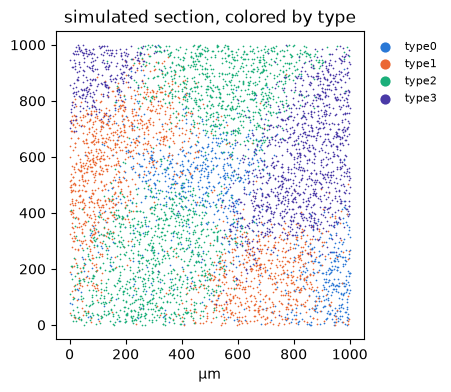

In [3]:
colors = np.array(["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"])
fig, ax = plt.subplots(figsize=(4.2, 4))
for g, name in enumerate(sorted(adata.obs["cell_type"].unique())):
    rows = (adata.obs["cell_type"] == name).to_numpy()
    xy = adata.obsm["spatial"][rows]
    ax.scatter(xy[:, 0], xy[:, 1], s=1.5, color=colors[g], label=name, lw=0)
ax.set_aspect("equal")
ax.set_xlabel("µm")
ax.legend(markerscale=6, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
ax.set_title("simulated section, colored by type");

## 2. Build the cell graph and fit once

`dc.build_graph` finds each cell's neighbors and the fixed spillover weights β. A fit then
needs a configuration. The defaults of `dc.Config` are the paper's settings. Here we shrink the
networks and the epoch budget so the fit takes seconds on a CPU. We fit at κ = 0.2, the true
value. On real tissue κ is unknown, which is why section 4 sweeps it.

In [4]:
dc.build_graph(adata, "cell_type")

config = dc.Config(
    label_key="cell_type", image_key="X_image", kappa=0.2, seed=0, device="cpu",
    # shrunk for a CPU demo; leave these at their defaults on real data
    tile_cells=1024, epochs=100, eval_every=5, w_warmup_epochs=10, patience=100,
    d_z=8, d_w=2, hidden=64, v_pcs=4)
model = dc.fit(adata, config)
summary = model.summary()
print(f"best epoch {summary['best_epoch']}, held-out reconstruction {summary['recon_val']:.3f}, "
      f"NMI of z with type {summary['nmi']:.2f}")
print(f"niche information in w above its permutation baseline: "
      f"{summary['niche_information_check']:.2f} nats")

best epoch 99, held-out reconstruction -2.768, NMI of z with type 0.80
niche information in w above its permutation baseline: 0.40 nats


The fit wrote its outputs into `adata`: the intrinsic state in `.obsm["X_discell_z"]`, the
response in `.obsm["X_discell_w"]`, the prior mean of the response in `.obsm["X_discell_mpsi"]`
and the response loadings in `.varm["discell_B"]`.

## 3. Intrinsic state versus response

z should sort cells by type and say nothing about the niche once the type is known. w should
follow the niche. Below, the niche of a cell is summarized by one number: the share of its
neighbors of type 1, minus the average for its own type.

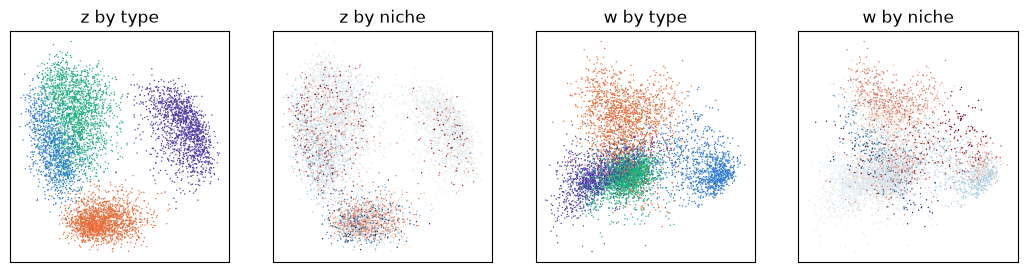

In [5]:
t = sim.t
niche = adata.obsm["discell_y"][:, 1].copy()
for g in range(4):
    niche[t == g] -= niche[t == g].mean()


def pcs(m):
    m = m - m.mean(0)
    return m @ np.linalg.svd(m, full_matrices=False)[2][:2].T


z, w = pcs(adata.obsm["X_discell_z"]), pcs(adata.obsm["X_discell_w"])
lim = np.percentile(np.abs(niche), 98)
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, xy, by, title in zip(axes, (z, z, w, w), ("type", "niche") * 2,
                             ("z by type", "z by niche", "w by type", "w by niche")):
    if by == "type":
        ax.scatter(xy[:, 0], xy[:, 1], s=1, c=colors[t], lw=0)
    else:
        ax.scatter(xy[:, 0], xy[:, 1], s=1, c=niche, cmap="RdBu_r", vmin=-lim, vmax=lim, lw=0)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

z separates the types, and within a type its color pattern is speckled: z carries little niche
information. w varies smoothly with the niche. w also differs between types, because the
response a niche calls for depends on the cell's type.

Since this is a simulation we can check recovery directly. We regress the true latents on the
fitted ones (the fitted latents are only defined up to a rotation, so a linear map is the
right comparison).

In [6]:
from sklearn.linear_model import LinearRegression


def r2(fitted, truth):
    return LinearRegression().fit(fitted, truth).score(fitted, truth)


print(f"true z from fitted z: R² = {r2(adata.obsm['X_discell_z'], sim.z_true):.2f}")
print(f"true w from fitted w: R² = {r2(adata.obsm['X_discell_w'], sim.w_true):.2f}")

true z from fitted z: R² = 0.89
true w from fitted w: R² = 0.42


z is recovered well. w is recovered less well in this short CPU run, though it still tracks
the niche as the plot shows.

## 4. The probe: how much niche signal is left in z?

During training an adversary tries to predict the niche from z (and the type), and z is trained
to defeat it. A defeated adversary proves little, so after training DisCell grades z with the
probe. The probe is fitted on training tiles and scored on held-out tiles. It reports how much
better it predicts the neighbor composition than the type alone, minus the same score on z
shuffled within type (the permutation baseline). That excess is the **residual niche
signal**. `var_fraction` reports it as 1 − e^(−2·excess), approximately the share of the
within-type variance that the probe explains beyond chance. The code scores the image
descriptor the same way, as a second block.

To see what the adversary does, we also fit the same model without it (`alpha_a=0`).

In [7]:
import dataclasses

reference = dc.fit(adata, dataclasses.replace(config, alpha_a=0.0))
model.encode(adata)             # put the main fit's latents back into adata

rows = []
for name, m in (("with adversary", model), ("without (alpha_a = 0)", reference)):
    probe = dc.evaluate.heldout_probe(m, adata)
    rows.append([name] + [probe[grader][block]["var_fraction"]
                          for grader in ("ridge", "mlp") for block in ("comp", "img")])
print(f"{'':24s}{'linear/types':>14s}{'linear/image':>14s}{'mlp/types':>12s}{'mlp/image':>12s}")
for name, *values in rows:
    print(f"{name:24s}" + "".join(f"{100 * v:13.1f}%" for v in values))

                          linear/types  linear/image   mlp/types   mlp/image
with adversary                    4.0%          2.0%          7.7%          2.9%
without (alpha_a = 0)             9.1%          6.6%         33.0%         18.9%


The adversary removes most of the niche signal that z would otherwise absorb, and the
nonlinear probe finds much more of it than the linear one when the adversary is off. The
residual is small but not zero. A probe at its baseline bounds the dependence it can detect;
it does not prove independence.

## 5. A tiny κ sweep and breakdown points

The counts limit how much spillover there can be, but never how little, so they cannot tell
us κ itself (see [docs/model.md](../docs/model.md), section 7). So we refit at several
assumed values and ask of each finding how much spillover it can survive. `fit_sweep` fits
every (κ, seed) pair and saves each fit, so an interrupted sweep resumes. `fit_draws` computes,
per fit, the paper's findings and their tile-bootstrap draws. `finding_breakdown` pools seeds
and returns each finding's breakdown point κ*, with its role in the paper: a
reported finding, a check of the fit, or a member counted in the Bonferroni correction but
not reported.

On this simulation three groups of findings are defined: the niche information in w
(`w_mi`, a check) and the relocation reads (`relocation_mean`, `relocation_distribution`). The
cell-cycle check, the signaling-gene lean and the tumor axis need real gene names or a tumor
type and are skipped. This takes about two minutes.

In [8]:
kappas, seeds = (0.0, 0.1, 0.2, 0.3, 0.4), (0, 1)
fits = dc.sensitivity.fit_sweep(adata, config, kappas=kappas, seeds=seeds, out_dir=work)

draws = {}
for (kappa, seed), fitted in fits.items():
    draws[(kappa, seed)] = f"{work}/k{kappa:g}_s{seed}/draws"
    dc.sensitivity.fit_draws(fitted, adata, groups=("w_mi", "relocation_mean", "relocation_distribution"),
                             n=200, min_cells=100, out_dir=draws[(kappa, seed)])
table = dc.sensitivity.finding_breakdown(draws, grid=kappas, seeds=seeds)

print(f"{len(table['members'])} findings, two-sided level {table['level']:.4f} (Bonferroni)")
for name, member in table["members"].items():
    star = "" if member["kappa_star"] is None else f"  kappa* = {member['kappa_star']:g}"
    print(f"  {name:28s} {member['status']}{star}  [{member['role']}]")

4 findings, two-sided level 0.9875 (Bonferroni)
  moved_vs_type_mean           no finding  [counted, not reported]
  moved_vs_random_cell         above the grid  [counted, not reported]
  relocation_finding           breaks  kappa* = 0.1  [finding]
  niche_information_check      above the grid  [check]


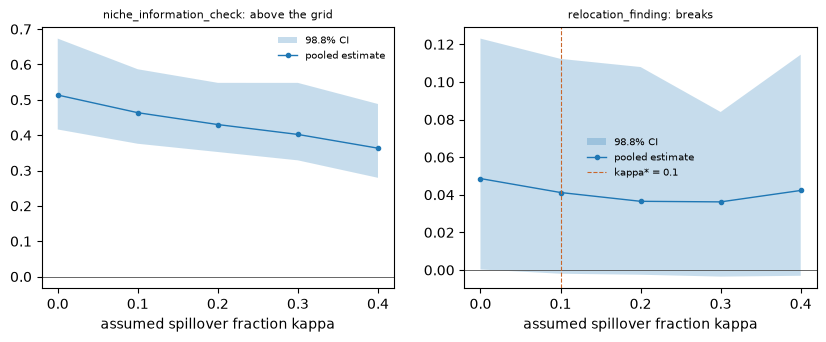

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
dc.pl.breakdown_trajectory(table, "niche_information_check", ax=axes[0])
dc.pl.breakdown_trajectory(table, "relocation_finding", ax=axes[1]);

How to read this:

* A finding **holds** at a κ when its interval lies entirely on the side of zero of its
  κ = 0 estimate. Each draw of the interval picks the fits with replacement, takes an
  independent tile draw for each pick and averages them, so the interval covers the spread
  between fits as well as over the tissue. Its breakdown point κ* is the first grid value where
  it does not hold.
* Here the true κ is 0.2. The plots show the niche information in w (a check of the fit) and
  the relocation finding (one of the paper's three findings). Neither breakdown
  point estimates κ. Each says how much spillover of the modeled form a finding can take
  before it could be spillover alone.
* `moved_vs_type_mean` and `moved_vs_random_cell`, two comparisons of moved cells, enter the
  Bonferroni correction, but the paper does not report them.
* Two seeds and 200 draws make wide intervals. Here the relocation finding
  breaks at 0.1 although the simulated response is genuine, because the two fits differ enough
  for its interval to reach zero. The paper used three seeds and 4,000 to 10,000 draws per fit.

## 6. How much spillover the counts allow: κ̄ and the decision rule

The counts limit κ from above. `kappa_bar` pools that bound over the connected cells of each
type, with an exact Poisson upper limit and a Bonferroni correction over genes, and reports
the largest type value as the section's κ̄. The model-based version takes the neighbors'
clean profiles from fits (the paper uses the three seeds at κ = 0.1; here the two seeds
at κ = 0.1). The counts-only version uses the neighbors' observed counts and needs no model.
`decide` then reads each breakdown point against κ̄, with the three outcomes of the paper's
Fig. 5. A finding *holds at the bound* (`safe` in the output) if it still holds at a tested κ
at or above κ̄, *breaks before the bound* (`not ruled out`) if it breaks before any tested κ
reaches κ̄, and is *undecided* if κ̄ lies above the tested range.

In [10]:
bound = dc.sensitivity.kappa_bar(adata, [fits[(0.1, 0)], fits[(0.1, 1)]])
for version in ("model_based", "counts_only"):
    b = bound[version]
    print(f"{version:12s} kappa_bar = {b['kappa_bar']:.3f} ({b['type']}); "
          f"smallest type value {b['min']:.3f} ({b['min_type']})")
for name, d in dc.sensitivity.decide(table, bound).items():
    print(f"  {name:28s} {d['status']:15s} -> {d['verdict']}")

model_based  kappa_bar = 0.258 (type2); smallest type value 0.146 (type1)
counts_only  kappa_bar = 0.363 (type2); smallest type value 0.229 (type1)
  moved_vs_type_mean           no finding      -> None
  moved_vs_random_cell         above the grid  -> safe
  relocation_finding           breaks          -> not ruled out
  niche_information_check      above the grid  -> safe


Both section values lie above the true κ of 0.2. The smallest type value of the model-based
version does not: these tiny CPU fits, at an assumed κ of 0.1, misplace some genes in the
clean profiles, and a few such genes set the minimum over a type. That is why the section
value is the largest type value, the loosest valid choice. κ̄ bounds spillover of the modeled
kind from above and never measures it. Here κ = 0.3 is the first tested value at or above
κ̄, so a finding that still holds there holds at the bound.

## 7. Test a finding of your own

Any signed number you can compute from one fit can be swept. Write it as a function of
per-cell weights (the bootstrap resamples 200 µm tiles by reweighting their cells), get its
draws with `finding_draws` on every fit, and pass them to `breakdown`.

As an example, take the claim "in type-0 cells, gene 41 responds to type-1 neighbors". On one
fit, the response part of gene 41 in each cell is its row of the gene-centered loadings `B`
times the cell's w. The finding is the weighted slope of that against the share of type-1
neighbors, within type 0. Gene 41 has a true response in this simulation.

In [11]:
def response_slope(fitted, gene=41, cell_type=0, neighbor_type=1):
    fitted.encode(adata)
    loadings = adata.varm["discell_B"] - adata.varm["discell_B"].mean(axis=0)
    response = adata.obsm["X_discell_w"] @ loadings[gene]
    rows = t == cell_type
    x, r = adata.obsm["discell_y"][rows, neighbor_type], response[rows]

    def statistic(weights):
        wt = weights[rows]
        xc = x - np.average(x, weights=wt)
        return float(np.sum(wt * xc * (r - np.average(r, weights=wt))) / np.sum(wt * xc ** 2))

    return statistic


mine = {}
for (kappa, seed), fitted in fits.items():
    entry = dc.sensitivity.finding_draws(adata.obsm["spatial"], response_slope(fitted),
                                          n=200, seed=seed)
    mine.setdefault(kappa, {})[seed] = entry
result = dc.sensitivity.breakdown({"gene41_response_slope": mine}, n_findings=1)
member = result["members"]["gene41_response_slope"]
print(member["status"], member["kappa_star"])
for kappa, entry in member["trajectory"].items():
    print(f"  kappa {kappa:>4s}: {entry['estimate']:+.3f}  "
          f"[{entry['ci'][0]:+.3f}, {entry['ci'][1]:+.3f}]")

above the grid None
  kappa    0: +0.332  [+0.264, +0.374]
  kappa  0.1: +0.265  [+0.210, +0.298]
  kappa  0.2: +0.221  [+0.171, +0.243]
  kappa  0.3: +0.185  [+0.151, +0.205]
  kappa  0.4: +0.115  [+0.044, +0.191]


Two cautions for your own findings. First, pick findings that are well defined under the
model's symmetries: the response programs can rotate, and each type's mean of w is arbitrary,
so use within-type comparisons and gene-centered loadings as above. Second, per-gene reads
borrow strength across genes, because the response has only `d_w` programs. A gene with no
response of its own can still show a response slope when it loads on a program. So read a
gene's response against the gene's other sources of variation in the type, its intrinsic
part and its spillover, rather than on its own. `dc.tl.gene_split` does this for every gene
of every type: it divides each gene's within-type variation into intrinsic, response and
spillover shares and assigns the gene only when one clearly dominates (see
[docs/use_cases.md](../docs/use_cases.md#split-each-genes-variation-within-a-type)).

`n_findings` sets the Bonferroni correction. If you test several findings, pass them together
so the correction covers all of them.

## Next

* [02_public_section.ipynb](02_public_section.ipynb) runs DisCell on a public 10x Xenium
  section: ingest, labels, fit, probe and relocation.
* [docs/use_cases.md](../docs/use_cases.md) lists what DisCell is for, with the function to
  call for each.